# 04 - PyPSA: putting it together

[PyPSA](https://pypsa.org) builds an energy system as buses, generators,
loads, links and stores, and finds the cheapest way to run it with a
linear program (HiGHS solver here).

This notebook takes the outputs of the first three:
- demand from **loadcast** (notebook 01)
- PV output and outdoor temperature from **pvlib** (notebook 02)
- heat pump COP vs temperature from **TESPy** (notebook 03)

and schedules a year of the plant with **perfect foresight** (it knows
every price and demand in advance). That's the best case, the ceiling
that forecasting can only get close to later.

Experiments:
1. Base case: heat pump + gas boiler, no storage
2. What does a hot water tank add? A battery?
3. Heat pump size
4. What happens with no backup boiler? (spoiler: it breaks)
5. Wholesale vs "retail-ish" electricity price: does the heat pump still win?

In [1]:
import sys
sys.path.insert(0, "..")
import logging
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pypsa

import config

plt.rcParams["figure.dpi"] = 72
logging.getLogger("pypsa").setLevel(logging.WARNING)
logging.getLogger("linopy").setLevel(logging.ERROR)   # infeasible runs are expected in experiment 4
print("pypsa", pypsa.__version__)

pypsa 1.2.4


## Inputs
Everything in **kW** and **$ per kWh**.

In [2]:
demand = pd.read_csv(config.DATA_DIR / "demand_loadcast.csv", index_col=0, parse_dates=True)
pv = pd.read_csv(config.DATA_DIR / "pv_and_weather.csv", index_col=0, parse_dates=True)
cop_map = pd.read_csv(config.DATA_DIR / "cop_map.csv")

# both are local standard time, no time zone; check they actually line up
assert (demand.index == pv.index).all(), "time indexes don't match"
hours = demand.index

# heat pump COP for every hour, interpolated from the TESPy map
cop = pd.Series(np.interp(pv.temp_air, cop_map.T_amb, cop_map.COP), index=hours)
print(f"COP over the year: min {cop.min():.2f}, mean {cop.mean():.2f}, max {cop.max():.2f}")

COP over the year: min 2.07, mean 2.60, max 3.34


### Electricity price

The plan is CAISO day-ahead prices from gridstatus. **When I ran this I
couldn't reach CAISO's servers**, so unless `data/prices_caiso.csv`
exists this uses a made-up "duck curve" price: cheap midday (lots of
solar on the grid, more so in spring), expensive in the evening. The
shape is roughly right for California, the numbers are invented.

To use real prices, set `DOWNLOAD_PRICES = True` (takes a while, it goes
month by month and CAISO rate-limits).

price source: MADE-UP duck curve (no CAISO data)


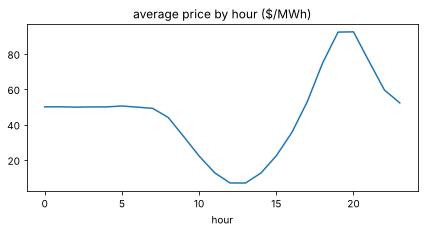

In [3]:
DOWNLOAD_PRICES = False
price_file = config.DATA_DIR / "prices_caiso.csv"

if DOWNLOAD_PRICES and not price_file.exists():
    import warnings
    import gridstatus
    warnings.filterwarnings("ignore", category=DeprecationWarning)
    # get_lmp() is "deprecated", but its replacement downloads every node in
    # CAISO. This one lets us ask for just one.
    caiso = gridstatus.CAISO()
    months = []
    for m in range(1, 13):
        start = pd.Timestamp(config.YEAR, m, 1)
        df = caiso.get_lmp(date=start, end=start + pd.offsets.MonthBegin(1),
                           market="DAY_AHEAD_HOURLY", locations=[config.CAISO_PRICE_NODE])
        months.append(df)
        print("got", start.strftime("%Y-%m"))
    raw = pd.concat(months)
    # CAISO times have DST; convert to our local standard time
    t = pd.to_datetime(raw["Interval Start"], utc=True).dt.tz_convert(config.TIMEZONE).dt.tz_localize(None)
    raw.assign(time=t).groupby("time").LMP.first().rename("usd_per_mwh").to_csv(price_file)

if price_file.exists():
    price = pd.read_csv(price_file, index_col=0, parse_dates=True).iloc[:, 0].reindex(hours).ffill() / 1000
    price_source = "CAISO day-ahead " + config.CAISO_PRICE_NODE
else:
    rng = np.random.default_rng(0)
    h = hours.hour.values
    spring = np.isin(hours.month, [3, 4, 5])
    solar_dip = np.clip(np.cos(2 * np.pi * (h - 12.5) / 24), 0, None) ** 2
    evening = np.exp(-((h - 19.5) ** 2) / 4)
    usd_per_mwh = 50 - 40 * solar_dip * np.where(spring, 1.4, 1.0) + 45 * evening + rng.normal(0, 6, len(h))
    price = pd.Series(usd_per_mwh / 1000, index=hours)
    price_source = "MADE-UP duck curve (no CAISO data)"

print("price source:", price_source)
price.groupby(hours.hour).mean().mul(1000).plot(figsize=(7, 3), title="average price by hour ($/MWh)")
plt.xlabel("hour");

### Other assumptions
- Gas: ~$8/MMBtu for an industrial customer = $0.027/kWh, boiler 90% efficient
- A "retail adder" for electricity (on top of wholesale) to roughly account for
  grid charges. Starts at zero, experiment 5 changes it.
- Sizes from the scoping doc where they exist

In [4]:
GAS_USD_PER_KWH = 0.027
BOILER_EFF = 0.90

base = dict(
    hp_kw_heat=1500,          # heat pump size in kW of HEAT at the mean COP
    boiler_kw=2500,
    tank_kwh=0,               # 0 = no tank
    battery_kwh=0,            # 0 = no battery
    battery_kw=500,
    pv_kwp=1000,
    retail_adder=0.0,         # $/kWh on top of wholesale
)

## The model

Two buses (electricity and heat). The heat pump is a `Link` from the
electricity bus to the heat bus whose efficiency is the hourly COP. The
tank is a `Store` on the heat bus.

In [5]:
def build_network(hp_kw_heat, boiler_kw, tank_kwh, battery_kwh, battery_kw, pv_kwp, retail_adder):
    n = pypsa.Network()
    n.set_snapshots(hours)

    # carriers are just labels, but PyPSA warns a lot without them
    n.add("Carrier", ["electricity", "heat", "gas"])
    n.add("Bus", "elec", carrier="electricity")
    n.add("Bus", "heat", carrier="heat")

    n.add("Load", "elec_demand", bus="elec", p_set=demand.elec_kw)
    n.add("Load", "heat_demand", bus="heat", p_set=demand.heat_kw)

    n.add("Generator", "grid", bus="elec", carrier="electricity", p_nom=5000, marginal_cost=price + retail_adder)
    n.add("Generator", "pv", bus="elec", carrier="electricity", p_nom=pv_kwp, p_max_pu=pv.pv_kw_per_kwp, marginal_cost=0)

    # p_nom of a Link is on the INPUT side (electricity), so convert
    n.add("Link", "heat_pump", bus0="elec", bus1="heat", carrier="heat",
          p_nom=hp_kw_heat / cop.mean(), efficiency=cop)
    if boiler_kw > 0:
        n.add("Generator", "gas_boiler", bus="heat", carrier="gas", p_nom=boiler_kw,
              marginal_cost=GAS_USD_PER_KWH / BOILER_EFF)

    if tank_kwh > 0:
        n.add("Store", "tank", bus="heat", carrier="heat", e_nom=tank_kwh, e_cyclic=True,
              standing_loss=0.002)   # 0.2% per hour
    if battery_kwh > 0:
        n.add("StorageUnit", "battery", bus="elec", carrier="electricity", p_nom=battery_kw,
              max_hours=battery_kwh / battery_kw, cyclic_state_of_charge=True,
              efficiency_store=0.95, efficiency_dispatch=0.95)
    return n


def run(**changes):
    settings = {**base, **changes}
    n = build_network(**settings)
    t0 = time.time()
    status, condition = n.optimize(solver_name="highs", solver_options={"output_flag": False},
                                   include_objective_constant=False, progress=False)
    solve_s = time.time() - t0
    if condition != "optimal":
        return n, {**changes, "status": condition, "solve_s": round(solve_s, 1)}

    heat_from_hp = n.links_t.p1["heat_pump"].abs().sum()
    heat_from_boiler = n.generators_t.p["gas_boiler"].sum() if "gas_boiler" in n.generators.index else 0
    result = {
        **changes,
        "status": condition,
        "annual_cost_$": n.objective,
        "grid_MWh": n.generators_t.p["grid"].sum() / 1000,
        "peak_grid_kW": n.generators_t.p["grid"].max(),
        "hp_share_of_heat": heat_from_hp / (heat_from_hp + heat_from_boiler),
        "pv_used_MWh": n.generators_t.p["pv"].sum() / 1000,
        "solve_s": round(solve_s, 1),
    }
    return n, result

## 1. Base case: heat pump + boiler, no storage

In [6]:
n_base, r = run()
pd.Series(r).to_frame("base")

,base
status,optimal
annual_cost_$,183283.488143
grid_MWh,3154.164638
peak_grid_kW,1146.999686
hp_share_of_heat,0.884567
pv_used_MWh,1282.663837
solve_s,2.2


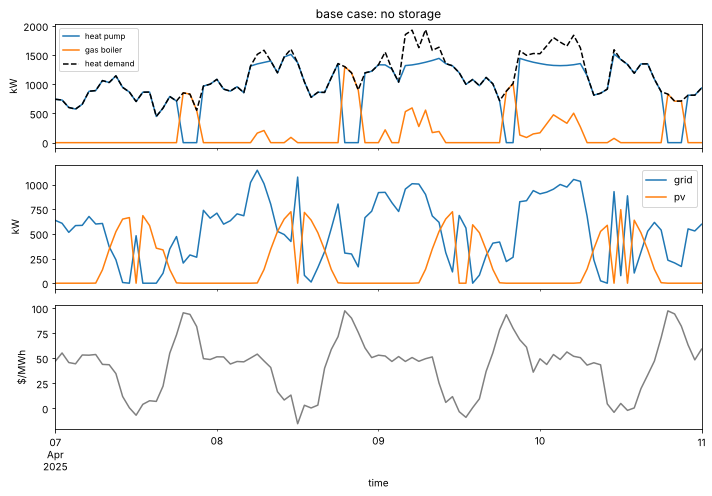

In [7]:
def plot_week(n, start=f"{config.YEAR}-04-07", days=4, title=""):
    w = slice(start, pd.Timestamp(start) + pd.offsets.Day(days))
    fig, ax = plt.subplots(3, 1, sharex=True, figsize=(10, 7))
    heat = pd.DataFrame({"heat pump": n.links_t.p1["heat_pump"].abs()})
    if "gas_boiler" in n.generators.index:
        heat["gas boiler"] = n.generators_t.p["gas_boiler"]
    if "tank" in n.stores.index:
        heat["tank (discharge +)"] = n.stores_t.p["tank"]
    heat.loc[w].plot(ax=ax[0], title=title or "heat supply")
    demand.heat_kw.loc[w].plot(ax=ax[0], color="k", ls="--", label="heat demand"); ax[0].legend(fontsize=8)
    ax[0].set_ylabel("kW")
    elec = pd.DataFrame({"grid": n.generators_t.p["grid"], "pv": n.generators_t.p["pv"]})
    elec.loc[w].plot(ax=ax[1]); ax[1].set_ylabel("kW")
    (price.loc[w] * 1000).plot(ax=ax[2], color="grey"); ax[2].set_ylabel("$/MWh")
    plt.tight_layout()

plot_week(n_base, title="base case: no storage")

Two things I didn't expect:
- The boiler still makes ~12% of the heat. On cold mornings the heat pump
  (sized at the *average* COP) can't make 1.5 MW, so the boiler tops up.
- Not all the PV gets used. With no tank or battery, on spring middays the
  (made-up) price goes negative, so the optimizer imports from the grid
  and gets paid for it, and curtails our own PV. There's no export in this
  model, so PV can't be sold.

## 2. Add a hot water tank, then a battery

In [8]:
results = []
for label, ch in [("no storage", {}),
                  ("tank 4 MWh", {"tank_kwh": 4000}),
                  ("tank 12 MWh", {"tank_kwh": 12000}),
                  ("battery 1 MWh", {"battery_kwh": 1000}),
                  ("tank 4 MWh + battery 1 MWh", {"tank_kwh": 4000, "battery_kwh": 1000})]:
    n, r = run(**ch)
    results.append({"case": label, **{k: v for k, v in r.items() if k not in ch}})
    if label == "tank 4 MWh":
        n_tank = n
storage = pd.DataFrame(results).set_index("case")
storage["saving_vs_no_storage_$"] = storage["annual_cost_$"].iloc[0] - storage["annual_cost_$"]
storage.round(2)

,status,annual_cost_$,grid_MWh,peak_grid_kW,hp_share_of_heat,pv_used_MWh,solve_s,saving_vs_no_storage_$
case,,,,,,,,
no storage,optimal,183283.49,3154.16,1147.0,0.88,1282.66,1.5,0.00
tank 4 MWh,optimal,148490.65,3216.21,1147.0,0.99,1483.36,3.0,34792.84
tank 12 MWh,optimal,136459.56,3142.83,1147.0,1.00,1572.99,3.1,46823.93
battery 1 MWh,optimal,151559.12,3168.50,1647.0,0.92,1439.98,3.7,31724.37
tank 4 MWh + battery 1 MWh,optimal,120437.97,3239.85,1647.0,0.99,1532.69,5.0,62845.52


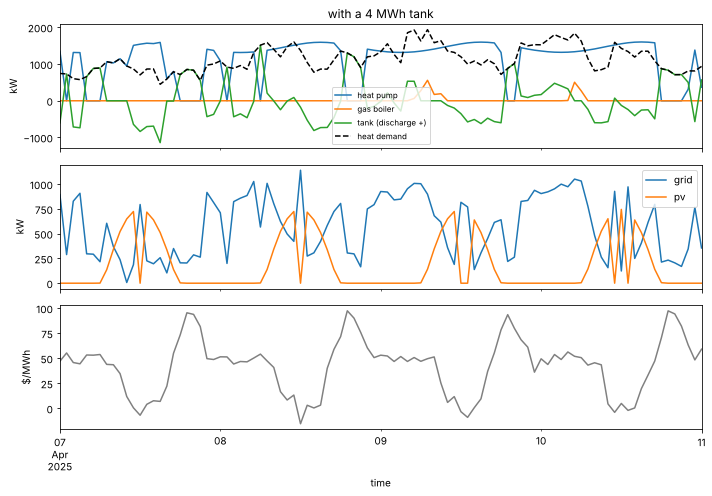

In [9]:
plot_week(n_tank, title="with a 4 MWh tank")

## 3. Heat pump size (with the 4 MWh tank)

In [10]:
rows = []
for hp in [500, 1000, 1500, 2000, 3000]:
    _, r = run(hp_kw_heat=hp, tank_kwh=4000)
    rows.append(r)
pd.DataFrame(rows).set_index("hp_kw_heat").round(2)

,tank_kwh,status,annual_cost_$,grid_MWh,peak_grid_kW,hp_share_of_heat,pv_used_MWh,solve_s
hp_kw_heat,,,,,,,,
500,4000,optimal,216203.42,2283.20,761.90,0.55,1210.00,2.4
1000,4000,optimal,168979.97,2977.80,954.45,0.89,1460.79,2.3
1500,4000,optimal,148490.65,3216.21,1147.00,0.99,1483.36,2.6
2000,4000,optimal,142081.27,3253.34,1339.55,1.00,1472.23,2.5
3000,4000,optimal,139060.08,3269.07,1724.65,1.00,1458.11,3.0


## 4. No backup boiler

In [11]:
rows = []
for hp, tank in [(1000, 4000), (1500, 4000), (2000, 4000), (2000, 0)]:
    _, r = run(hp_kw_heat=hp, tank_kwh=tank, boiler_kw=0)
    rows.append(r)
pd.DataFrame(rows).round(2)

,hp_kw_heat,tank_kwh,boiler_kw,status,solve_s,annual_cost_$,grid_MWh,peak_grid_kW,hp_share_of_heat,pv_used_MWh
0,1000,4000,0,infeasible,1.7,NaN,NaN,NaN,NaN,NaN
1,1500,4000,0,infeasible,1.6,NaN,NaN,NaN,NaN,NaN
2,2000,4000,0,optimal,2.4,142134.21,3265.49,1339.55,1.0,1472.67
3,2000,0,0,infeasible,1.6,NaN,NaN,NaN,NaN,NaN


## 5. Wholesale vs retail-ish electricity

A real industrial customer pays a lot more than the wholesale price
(transmission, distribution, other charges). I don't have a real PG&E
tariff in here yet, so this just adds a flat amount per kWh.

In [12]:
rows = []
for adder in [0.0, 0.02, 0.04, 0.06, 0.10]:
    _, r = run(retail_adder=adder, tank_kwh=4000)
    rows.append(r)
pd.DataFrame(rows).set_index("retail_adder").round(2)

,tank_kwh,status,annual_cost_$,grid_MWh,peak_grid_kW,hp_share_of_heat,pv_used_MWh,solve_s
retail_adder,,,,,,,,
0.00,4000,optimal,148490.65,3216.21,1147.00,0.99,1483.36,2.6
0.02,4000,optimal,207202.12,2548.96,1147.00,0.83,1651.90,3.0
0.04,4000,optimal,248960.44,1710.82,1066.27,0.53,1651.90,2.4
0.06,4000,optimal,280255.54,1431.77,804.47,0.43,1651.90,2.7
0.10,4000,optimal,331328.30,1198.39,569.35,0.34,1651.90,2.9


## Notes to self

- **The tank is the big win.** A 4 MWh tank cuts cost ~19% and lets the
  heat pump cover ~99% of the heat. Going to 12 MWh adds less.
- **The battery looks too good**, and I don't trust it: ~$32k/yr for 1 MWh.
  That's because my made-up price swings ~$90/MWh every day and goes
  negative. Needs real CAISO prices before I believe it. Also, the battery
  pushes peak grid import from 1,147 to 1,647 kW (charging at full power on
  cheap hours). With a demand charge that would cost money, which this
  model doesn't see yet.
- **Heat pump size:** 1 MW is clearly too small (boiler makes 11% of the
  heat even with the tank), 1.5 MW is the knee, above 2 MW barely helps.
- **No boiler = infeasible** unless the heat pump is 2 MW *and* there's a
  tank. "1.5 MW" at the average COP is only ~1.2 MW on a cold morning
  (COP 2.07), and the 2 MW demand peaks don't fit. An infeasible LP just
  says "infeasible", it doesn't tell you which hour broke. Next time: add
  an expensive "unmet heat" generator so it always solves and I can see
  where the gap is.
- **The electricity tariff decides everything.** At wholesale prices the
  heat pump does 99% of the heat. Adding $0.04/kWh of grid charges drops
  that to about half, and at $0.10/kWh the boiler does two thirds. A real
  PG&E industrial tariff (energy + demand charges) is the most important
  missing input.
- A full year solves in ~2 s with HiGHS. Fast enough to run lots of cases.